# N-граммная языковая модель

Построим модель, которая продолжает обращение по частотам соседних слов. Сначала проверим её на трёх предложениях из лекции, затем сравним униграммы, биграммы и триграммы на корпусе «Север». В конце прочитаем несколько продолжений и попробуем объяснить, почему они получились именно такими.

In [1]:
from pathlib import Path
import os
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Находим корень раздачи независимо от места запуска Jupyter.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "requests.csv").exists())
DATA = ROOT / "data"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (8, 4)})


## Подготовка последовательностей

Берём по одному обращению из каждой группы. Токенизатор выделяет слова и числа; пунктуация в этой работе не предсказывается. `BOS` задаёт начало истории, `EOS` обозначает предсказываемое завершение, `UNK` заменяет слова вне словаря.

Функция `events` уже написана. Она выдаёт пары «история, следующий токен» и начинает историю заново для каждого предложения. Посмотрите на пример её работы перед тем, как писать счётчики.

In [2]:
from collections import Counter, defaultdict
import math

BOS, EOS, UNK = "<BOS>", "<EOS>", "<UNK>"
def tokenize(text):
    return re.findall(r"[а-яёa-z0-9]+", text.lower())

df = pd.read_csv(DATA / "requests.csv", keep_default_na=False).drop_duplicates("group_id")
parts = {name: [tokenize(t) for t in df.loc[df["split"].eq(name), "text"]]
         for name in ["train", "validation", "test"]}
assert tokenize("Студент читает книгу") == ["студент", "читает", "книгу"]
print({name: len(values) for name, values in parts.items()})

# Готовый итератор отделяет устройство истории от подсчёта частот.
def events(sentence, n):
    sequence = [BOS] * (n - 1) + list(sentence) + [EOS]
    for t in range(n - 1, len(sequence)):
        history = tuple(sequence[t - n + 1:t]) if n > 1 else ()
        yield history, sequence[t]


{'train': 72, 'validation': 24, 'test': 24}


In [3]:
demo_sentence = tokenize("студент читает книгу")
for history, target in events(demo_sentence, 2):
    print(history, "→", target)

('<BOS>',) → студент
('студент',) → читает
('читает',) → книгу
('книгу',) → <EOS>


У биграммы в истории один токен. Последняя цель — EOS, а первая история — BOS. Для триграммы перед первым словом появились бы два BOS, но число целей осталось бы тем же.

## 1. Общий словарь

Посчитайте частоты слов только в `parts["train"]`. Сохраните множество слов с частотой не меньше двух в `known`. Создайте отсортированный список `vocab`, добавив `EOS` и `UNK` и исключив `BOS`.

Создайте `encoded`: словарь с ключами train, validation, test и списками токенизированных предложений. Во всех частях заменяйте слова вне `known` на `UNK`. Посчитайте долю UNK среди обычных слов каждой части, без EOS. Что эта доля говорит о сохранённых различиях текста?

In [4]:
word_counts = Counter(t for sentence in parts["train"] for t in sentence)
known = {t for t, c in word_counts.items() if c >= 2}
vocab = sorted(known | {EOS, UNK})
encoded = {name: [[t if t in known else UNK for t in sentence] for sentence in sentences]
           for name, sentences in parts.items()}
print("Размер словаря:", len(vocab))
coverage = {}
for name, sentences in encoded.items():
    words = [t for sentence in sentences for t in sentence]
    coverage[name] = {"words": len(words), "unk_fraction": words.count(UNK) / len(words)}
print(json.dumps(coverage, ensure_ascii=False, indent=2))

Размер словаря: 47
{
  "train": {
    "words": 455,
    "unk_fraction": 0.5802197802197803
  },
  "validation": {
    "words": 165,
    "unk_fraction": 0.6848484848484848
  },
  "test": {
    "words": 166,
    "unk_fraction": 0.7108433734939759
  }
}


In [5]:
assert BOS not in vocab and EOS in vocab and UNK in vocab
assert all(t in vocab for sentences in encoded.values() for sentence in sentences for t in sentence)
assert len(encoded["train"]) == 72 and len(encoded["validation"]) == len(encoded["test"]) == 24

Получается 47 выходных элементов. Доля UNK: около 58,02% на train, 68,48% на validation и 71,08% на test. Это высокая потеря словарных различий, которую нужно учитывать при чтении perplexity.

## 2. Счётчики переходов

Напишите `fit_model(sentences, n, vocab)` с помощью `events`. Для каждой истории считайте отдельные продолжения. Верните словарь с полями `n`, `vocab` (tuple), `counts` (история → Counter токенов), `totals` (история → общее число продолжений).

Проверьте три предложения из лекции. После «студент» должны получиться два «читает» и одно «возвращает». Объясните, почему всего целей двенадцать, хотя обычных слов девять.

In [6]:
def fit_model(sentences, n, vocab):
    if n < 1 or BOS in vocab or EOS not in vocab or UNK not in vocab:
        raise ValueError("Некорректный порядок или словарь")
    counts, totals = defaultdict(Counter), Counter()
    for sentence in sentences:
        for history, target in events(sentence, n):
            if target not in vocab:
                raise ValueError("Цель отсутствует в фиксированном словаре")
            counts[history][target] += 1
            totals[history] += 1
    return {"n": n, "vocab": tuple(vocab), "counts": dict(counts), "totals": totals}

toy_sentences = [tokenize(t) for t in ["студент читает книгу", "студент читает журнал", "студент возвращает книгу"]]
toy_vocab = sorted({t for s in toy_sentences for t in s} | {EOS, UNK})
toy_model = fit_model(toy_sentences, 2, toy_vocab)
print(toy_model["counts"][("студент",)])
print(toy_model["counts"][("читает",)])

Counter({'читает': 2, 'возвращает': 1})
Counter({'книгу': 1, 'журнал': 1})


In [7]:
toy_sentences = [tokenize(t) for t in ["студент читает книгу", "студент читает журнал", "студент возвращает книгу"]]
toy_vocab = sorted({t for s in toy_sentences for t in s} | {EOS, UNK})
toy_model = fit_model(toy_sentences, 2, toy_vocab)
assert len(toy_vocab) == 7
assert toy_model["counts"][("студент",)]["читает"] == 2
assert toy_model["totals"][("студент",)] == 3
assert sum(toy_model["totals"].values()) == 12  # 9 слов + 3EOS
assert all(BOS not in continuation for continuation in toy_model["counts"].values())

К девяти словам добавлены три EOS. Истории соседних предложений не соединяются. BOS присутствует только слева в парах, но не в выходном словаре.

## 3. Вероятность нового продолжения

Реализуйте `probability(model, history, target, alpha=0.1)` по add-alpha. При `alpha <= 0` или цели вне словаря вызывайте `ValueError`. Для невстречавшейся истории счётчики равны нулю.

Готовая `distribution` собирает значения в порядке `model["vocab"]`. Примените её к истории «студент» при alpha=1 и сверьте семь вероятностей с лекцией. Затем возьмите невстречавшуюся историю. Почему у неё получается равномерное распределение?

In [8]:
def probability(model, history, target, alpha=0.1):
    if alpha <= 0 or target not in model["vocab"]:
        raise ValueError("Нужно alpha>0 и цель из словаря")
    history = tuple(history)
    c = model["counts"].get(history, {}).get(target, 0)
    total = model["totals"].get(history, 0)
    return (c + alpha) / (total + alpha * len(model["vocab"]))

def distribution(model, history, alpha=0.1):
    return np.array([probability(model, history, t, alpha) for t in model["vocab"]])

print(dict(zip(toy_vocab, distribution(toy_model, ("студент",), alpha=1))))

{'<EOS>': np.float64(0.1), '<UNK>': np.float64(0.1), 'возвращает': np.float64(0.2), 'журнал': np.float64(0.1), 'книгу': np.float64(0.1), 'студент': np.float64(0.1), 'читает': np.float64(0.3)}


In [9]:
assert np.isclose(probability(toy_model, ("студент",), "читает", 1), 0.3)
assert np.isclose(probability(toy_model, ("студент",), "возвращает", 1), 0.2)
for h in [(BOS,), ("студент",), ("невстречавшаяся_история",)]:
    p = distribution(toy_model, h, 1)
    assert (p > 0).all() and np.isclose(p.sum(), 1)
assert np.allclose(distribution(toy_model, ("невстречавшаяся_история",), 1), np.ones(7)/7)

После «студент» вероятности читает/возвращает равны 0,3/0,2, остальные пять — 0,1. Добавка меняет и числитель, и знаменатель. Для новой истории каждый элемент получает 1/7.

## 4. Perplexity и выбор порядка

Напишите `evaluate_ppl(model, sentences, alpha=0.1)`. Суммируйте −ln вероятностей целей, включая EOS. Верните словарь `ppl`, `mean_nll`, `targets`. При отсутствии целевых событий вызывайте `ValueError`; одно пустое предложение всё ещё содержит цель EOS.

Создайте `models` для n=1,2,3 на одном `encoded["train"]`. Соберите DataFrame `comparison` с колонками `n`, `train_ppl`, `validation_ppl`, `train_targets`, `validation_targets`. Выберите `selected_n` по наименьшей validation perplexity, при равенстве — меньший n. Сохраните модель в `selected`, её тестовую оценку — в `test_result`.

Словарь и alpha остаются общими. Почему число целей в одной части должно совпадать у всех трёх порядков?

,n,train_ppl,validation_ppl,train_targets,validation_targets
0,1,9.694419,6.638790,527,189
1,2,5.248427,4.979994,527,189
2,3,5.044076,6.038190,527,189


Выбран n: 2 Тест: {'ppl': 4.940421045685083, 'mean_nll': 1.5974505594878547, 'targets': 190}


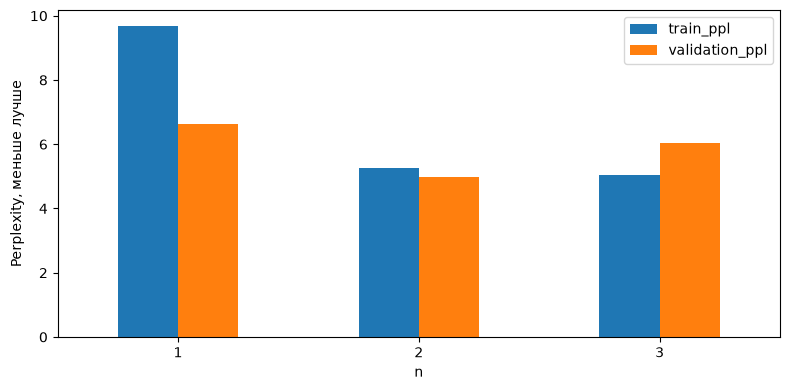

In [10]:
def evaluate_ppl(model, sentences, alpha=0.1):
    nll, targets = 0.0, 0
    for sentence in sentences:
        for history, target in events(sentence, model["n"]):
            nll -= math.log(probability(model, history, target, alpha))
            targets += 1
    if targets == 0:
        raise ValueError("Корпус не содержит целевых позиций")
    return {"ppl": math.exp(nll/targets), "mean_nll": nll/targets, "targets": targets}

models = {n: fit_model(encoded["train"], n, vocab) for n in [1, 2, 3]}
rows = []
for n, model in models.items():
    a, b = evaluate_ppl(model, encoded["train"]), evaluate_ppl(model, encoded["validation"])
    rows.append({"n": n, "train_ppl": a["ppl"], "validation_ppl": b["ppl"],
                 "train_targets": a["targets"], "validation_targets": b["targets"]})
comparison = pd.DataFrame(rows)
selected_n = int(comparison.sort_values(["validation_ppl", "n"]).iloc[0]["n"])
selected = models[selected_n]
test_result = evaluate_ppl(selected, encoded["test"])
display(comparison)
print("Выбран n:", selected_n, "Тест:", test_result)
comparison.set_index("n")[["train_ppl", "validation_ppl"]].plot.bar(rot=0)
plt.ylabel("Perplexity, меньше лучше"); plt.tight_layout(); plt.show()

In [11]:
assert comparison["train_targets"].nunique() == comparison["validation_targets"].nunique() == 1
assert test_result["targets"] == sum(len(s)+1 for s in encoded["test"])
assert math.isfinite(test_result["ppl"]) and test_result["ppl"] >= 1
assert evaluate_ppl(selected, [[]])["targets"] == 1
assert np.isclose(math.exp(-np.log([0.5, 0.25, 0.5]).mean()), 16**(1/3))

По валидации выбирается n=2. У n=3 обучающая perplexity ниже, но валидационная выше. Число целей не зависит от длины истории: 527/189/190 для train/validation/test.

## 5. Продолжаем префикс

Закончите `generate(model, prefix="как", mode="sample", seed=42, max_new=40)`. Преобразуйте префикс тем же словарём. На каждом шаге получите распределение по последним n−1 токенам; для униграммы история пустая. В greedy выбирайте максимум, в sample используйте `rng.choice` с вероятностями.

При EOS завершайте генерацию, иначе продолжайте до `max_new`. Верните `text` (префикс и продолжение), `tokens` (только новые токены без EOS), `stopped_by` ("EOS" или "limit") и `steps` (число новых предсказаний, включая EOS, если он появился). Оставляйте UNK видимым.

Соберите `generations`: один результат greedy и sampling с seed 7, 42 и 99. Сравните повтор с одним seed и результаты разных seed. Чем условия этого опыта отличаются от расчёта perplexity?

In [12]:
def generate(model, prefix="как", mode="sample", seed=42, max_new=40):
    if mode not in {"greedy", "sample"} or max_new < 1:
        raise ValueError("Проверьте режим и лимит")
    rng = np.random.default_rng(seed)
    prefix_tokens = [t if t in known else UNK for t in tokenize(prefix)]
    history_tokens = [BOS]*(model["n"]-1) + prefix_tokens
    generated = []
    for step in range(max_new):
        history = tuple(history_tokens[-(model["n"]-1):]) if model["n"] > 1 else ()
        p = distribution(model, history)
        index = int(np.argmax(p)) if mode == "greedy" else int(rng.choice(len(p), p=p))
        token = model["vocab"][index]
        if token == EOS:
            return {"text": " ".join(prefix_tokens + generated), "tokens": generated,
                    "stopped_by": "EOS", "steps": step+1}
        generated.append(token); history_tokens.append(token)
    return {"text": " ".join(prefix_tokens + generated), "tokens": generated,
            "stopped_by": "limit", "steps": max_new}

generations = {"greedy": generate(selected, mode="greedy")}
for seed in [7, 42, 99]:
    generations[f"sample_{seed}"] = generate(selected, seed=seed)
for name, result in generations.items():
    print(name, result)

greedy {'text': 'как <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK> <UNK>', 'tokens': ['<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>', '<UNK>'], 'stopped_by': 'limit', 'steps': 40}
sample_7 {'text': 'как подать социальной стипендии', 'tokens': ['подать', 'социальной', 'стипендии'], 'stopped_by': 'EOS', 'steps': 4}
sample_42 {'text': 'как получить другую сообщить о <UNK> стипендии можно ли <UNK> <UNK> <UNK> после из продлить другую выплаты не <UNK> к ли можно ли узнать социальной стипендии', 'tokens': ['по

In [13]:
assert generate(selected, seed=42) == generate(selected, seed=42)
for result in [generate(selected, mode="greedy"), generate(selected, seed=7)]:
    assert 1 <= result["steps"] <= 40
    assert result["stopped_by"] in {"EOS", "limit"}
    assert all(t in vocab and t not in {BOS, EOS} for t in result["tokens"])
    if result["stopped_by"] == "limit": assert len(result["tokens"]) == 40

Greedy повторяет UNK до предела. Seed 7 даёт короткое «как подать социальной стипендии», затем EOS на четвёртом предсказании. При генерации следующий вход зависит от собственного выбора, а при оценке берётся эталонная история.

## Состояние после нулевого входа

Следующая ячейка воспроизводит скалярную RNN из лекции. Параметры заданы вручную. Сначала предскажите знак второго состояния, затем сравните цепочку входов (1;0) с (0;0).

In [14]:
# Скалярная RNN из лекции: параметры заданы вручную, обучение не выполняется.
h = 0.0
for x in [1.0, 0.0]:
    h = np.tanh(0.5*h + x)
    print("input", x, "state", h)

input 1.0 state 0.7615941559557649
input 0.0 state 0.36339948438905245


## Что получилось

Словарь из 47 элементов объединил много исходных слов в UNK: 58,02% на train, 68,48% на validation и 71,08% на test. Модель различает последовательности после этой замены. Абсолютную perplexity следует читать вместе с покрытием словаря.

У n=1 обучающая/валидационная perplexity равна примерно 9,6944/6,6388, у n=2 — 5,2484/4,9800, у n=3 — 5,0441/6,0382. Выбран n=2. Его тестовая perplexity составляет 4,9404, средняя потеря 1,5975 на 190 целях. Триграмма лучше описала обучение, но хуже предсказывала новые истории. Более низкая perplexity отложенных частей относительно train также связана с составом целей: там выше доля объединённых UNK.

Greedy после «как» выдал 40 UNK и остановился по пределу. В этом состоянии максимум продолжения снова приходится на тот же маркер. Sampling с seed 7 дал «как подать социальной стипендии» и завершился EOS на четвёртом предсказании. Seed 42 завершился на шаге 26, seed 99 — на 31. Выборка внесла разнообразие, но не восстановила потерянные слова и не обеспечила грамматическую связность.

В скалярной RNN состояния равны примерно 0,761594 и 0,363399. При двух нулях оба состояния были бы нулевыми. Различие возникает из рекуррентного слагаемого 0,5h: второй выход зависит и от прошлого. Это демонстрация обновления, а не результат обучения нейросети.

На защите полезно предложить новый трёхтокенный путь и попросить назвать его вероятность и число целей. Затем поменять длину истории при сохранении самих целей: счётчики условных переходов изменятся, знаменатель среднего по позициям — нет.
